# TP 2

In [24]:
import duckdb
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.naive_bayes import GaussianNB
from sklearn.mixture import GaussianMixture
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import f1_score, roc_auc_score
import xgboost as xgb
import lightgbm as lgb

In [ ]:
con = duckdb.connect('accidents_france.db')

con.execute("DROP TABLE IF EXISTS lieux")
con.execute("DROP TABLE IF EXISTS usagers")
con.execute("DROP TABLE IF EXISTS vehicules")
con.execute("DROP TABLE IF EXISTS caracteristiques")
con.execute("DROP TABLE IF EXISTS accidents_complet")


con.execute("""
CREATE TABLE IF NOT EXISTS caracteristiques (
    Num_Acc BIGINT PRIMARY KEY,
    jour INTEGER,
    mois INTEGER,
    an INTEGER,
    hrmn VARCHAR,
    lum INTEGER,
    dep VARCHAR,
    com VARCHAR,
    agg INTEGER,
    int INTEGER,
    atm INTEGER,
    col INTEGER,
    adr TEXT,
    lat DOUBLE,
    long DOUBLE
);
""")

con.execute("""
CREATE TABLE IF NOT EXISTS lieux (
    Num_Acc BIGINT PRIMARY KEY,
    catr INTEGER,
    voie VARCHAR,
    v1 VARCHAR,       -- Changed to VARCHAR for "N/A"
    v2 VARCHAR,
    circ INTEGER,
    nbv INTEGER,
    vosp INTEGER,
    prof INTEGER,
    pr VARCHAR,       -- Changed to VARCHAR for spaces (e.g., "1 630")
    pr1 VARCHAR,      -- Changed to VARCHAR for spaces
    plan INTEGER,
    lartpc DOUBLE,
    larrout DOUBLE,
    surf INTEGER,
    infra INTEGER,
    situ INTEGER,
    vma INTEGER
);
""")

con.execute("""
CREATE TABLE IF NOT EXISTS vehicules (
    Num_Acc BIGINT,
    id_vehicule BIGINT PRIMARY KEY,
    num_veh VARCHAR,
    senc INTEGER,
    catv INTEGER,
    obs INTEGER,
    obsm INTEGER,
    choc INTEGER,
    manv INTEGER,
    motor INTEGER,
    occutc INTEGER,
    FOREIGN KEY (Num_Acc) REFERENCES caracteristiques (Num_Acc)
);
""")

con.execute("""
CREATE TABLE IF NOT EXISTS usagers (
    Num_Acc BIGINT,
    id_usager BIGINT PRIMARY KEY,
    id_vehicule BIGINT,
    num_veh VARCHAR,
    place INTEGER,
    catu INTEGER,
    grav INTEGER,
    sexe INTEGER,
    an_nais INTEGER,
    trajet INTEGER,
    secu1 INTEGER,
    secu2 INTEGER,
    secu3 INTEGER,
    locp INTEGER,
    actp VARCHAR,
    etatp INTEGER,
    FOREIGN KEY (Num_Acc) REFERENCES caracteristiques (Num_Acc),
    FOREIGN KEY (id_vehicule) REFERENCES vehicules (id_vehicule)
);
""")

print("Database schema created successfully!")

con.execute("COPY caracteristiques FROM 'caract-2023.csv' (HEADER, DELIMITER ';', DECIMAL_SEPARATOR ',');")
con.execute(r"""
INSERT INTO lieux
SELECT DISTINCT ON (Num_Acc)  -- This ensures each Num_Acc is only inserted once
    Num_Acc, 
    TRY_CAST(catr AS INTEGER), 
    voie, 
    v1, 
    v2, 
    TRY_CAST(circ AS INTEGER), 
    TRY_CAST(nbv AS INTEGER), 
    TRY_CAST(vosp AS INTEGER), 
    TRY_CAST(prof AS INTEGER),
    regexp_replace(replace(pr, chr(160), ''), ' ', '', 'g'), 
    regexp_replace(replace(pr1, chr(160), ''), ' ', '', 'g'),
    TRY_CAST(plan AS INTEGER), 
    TRY_CAST(replace(lartpc, ',', '.') AS DOUBLE), 
    TRY_CAST(replace(larrout, ',', '.') AS DOUBLE),
    TRY_CAST(surf AS INTEGER), 
    TRY_CAST(infra AS INTEGER), 
    TRY_CAST(situ AS INTEGER), 
    TRY_CAST(vma AS INTEGER)
FROM read_csv('lieux-2023.csv', 
              header=True, 
              delim=';', 
              quote='"', 
              all_varchar=True)
ORDER BY Num_Acc; -- Required when using DISTINCT ON
""")
con.execute("DELETE FROM vehicules;")
con.execute(r"""
INSERT INTO vehicules
SELECT DISTINCT ON (id_veh_val)
    Num_Acc,
    CAST(regexp_replace(replace(id_vehicule, chr(160), ''), ' ', '', 'g') AS BIGINT) AS id_veh_val,
    num_veh,
    TRY_CAST(senc AS INTEGER),
    TRY_CAST(catv AS INTEGER),
    TRY_CAST(obs AS INTEGER),
    TRY_CAST(obsm AS INTEGER),
    TRY_CAST(choc AS INTEGER),
    TRY_CAST(manv AS INTEGER),
    TRY_CAST(motor AS INTEGER),
    TRY_CAST(occutc AS INTEGER)
FROM read_csv('vehicules-2023.csv', 
              header=True, 
              delim=';', 
              quote='"', 
              all_varchar=True)
ORDER BY id_veh_val;
""")
print("1. Vehicules imported successfully.")

con.execute("DELETE FROM usagers;")
con.execute(r"""
INSERT INTO usagers
SELECT DISTINCT ON (id_usager_val)
    Num_Acc,
    CAST(regexp_replace(replace(id_usager, chr(160), ''), ' ', '', 'g') AS BIGINT) AS id_usager_val,
    CAST(regexp_replace(replace(id_vehicule, chr(160), ''), ' ', '', 'g') AS BIGINT) AS id_veh_val,
    num_veh,
    TRY_CAST(place AS INTEGER),
    TRY_CAST(catu AS INTEGER),
    TRY_CAST(grav AS INTEGER),
    TRY_CAST(sexe AS INTEGER),
    TRY_CAST(an_nais AS INTEGER),
    TRY_CAST(trajet AS INTEGER),
    TRY_CAST(secu1 AS INTEGER),
    TRY_CAST(secu2 AS INTEGER),
    TRY_CAST(secu3 AS INTEGER),
    TRY_CAST(locp AS INTEGER),
    actp,
    TRY_CAST(etatp AS INTEGER)
FROM read_csv('usagers-2023.csv', 
              header=True, 
              delim=';', 
              quote='"', 
              all_varchar=True)
-- Only import users if their vehicle ID exists in the vehicules table
WHERE CAST(regexp_replace(replace(id_vehicule, chr(160), ''), ' ', '', 'g') AS BIGINT) 
      IN (SELECT id_vehicule FROM vehicules)
ORDER BY id_usager_val;
""")
print("2. Usagers imported successfully.")

print("Data inserted successfully!")

Database schema created successfully!
1. Vehicules imported successfully.
2. Usagers imported successfully.
Data inserted successfully!


In [26]:
%load_ext sql
%sql con --alias duckdb
%sql SELECT catv, COUNT(*) FROM vehicules GROUP BY catv ORDER BY 2 DESC LIMIT 5

The sql extension is already loaded. To reload it, use:
  %reload_ext sql


Running query in 'duckdb'

catv,count_star()
7,54620
33,7688
10,6853
1,5116
2,3306


Dimensions de la base fusionnée : (125789, 42)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 125789 entries, 0 to 125788
Data columns (total 42 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Num_Acc      125789 non-null  int64  
 1   jour         125789 non-null  int32  
 2   mois         125789 non-null  int32  
 3   an           125789 non-null  int32  
 4   hrmn         125789 non-null  object 
 5   lum          125789 non-null  int32  
 6   dep          125789 non-null  object 
 7   com          125789 non-null  object 
 8   agg          125789 non-null  int32  
 9   int          125789 non-null  int32  
 10  atm          125789 non-null  int32  
 11  col          125789 non-null  int32  
 12  adr          124796 non-null  object 
 13  lat          125789 non-null  float64
 14  long         125789 non-null  float64
 15  catr         125789 non-null  int32  
 16  voie         125766 non-null  object 
 17  circ         125789 

,Num_Acc,jour,mois,an,lum,agg,int,atm,col,lat,...,an_nais,trajet,secu1,locp,catv,obs,obsm,choc,manv,motor
min,2.023000e+11,1.000000,1.000000,2023.0,-1.000000,1.000000,-1.000000,-1.000000,-1.000000,-23.372504,...,1913.0,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
max,2.023001e+11,31.000000,12.000000,2023.0,5.000000,2.000000,9.000000,9.000000,7.000000,51.047490,...,2023.0,9.000000,9.000000,9.000000,99.000000,17.000000,9.000000,9.000000,26.000000,6.000000
median,2.023000e+11,15.000000,7.000000,2023.0,1.000000,2.000000,1.000000,1.000000,3.000000,47.798380,...,1988.0,4.000000,1.000000,-1.000000,7.000000,0.000000,2.000000,2.000000,2.000000,1.000000
mean,2.023000e+11,15.397245,6.747323,2023.0,1.934827,1.604671,2.085222,1.627352,3.763652,44.113166,...,1984.329433,3.128692,1.932323,-0.236046,13.115551,1.147811,1.574216,2.852499,6.715293,1.251858


Répartition de la mortalité :
mortalite
0    97.298651
1     2.701349
Name: proportion, dtype: float64


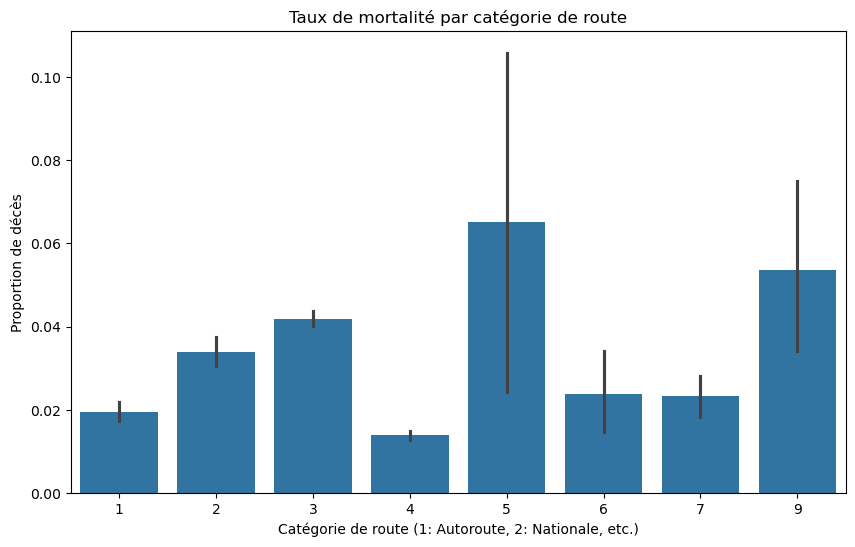

Variables les plus corrélées à la mortalité :
 mortalite    1.000000
obs          0.083554
locp         0.071272
situ         0.066277
col          0.063469
vma          0.060048
plan         0.055174
circ         0.037625
place        0.033620
trajet       0.032889
Name: mortalite, dtype: float64


In [ ]:
con.execute("""
CREATE TABLE accidents_complet AS
SELECT 
    c.*, 
    l.catr, l.voie, l.circ, l.nbv, l.vosp, l.prof, l.plan, l.surf, l.infra, l.situ, l.vma,
    u.id_usager, u.id_vehicule, u.place, u.catu, u.grav, u.sexe, u.an_nais, u.trajet, u.secu1, u.locp,
    v.catv, v.obs, v.obsm, v.choc, v.manv, v.motor
FROM usagers u
JOIN caracteristiques c ON u.Num_Acc = c.Num_Acc
JOIN lieux l ON u.Num_Acc = l.Num_Acc
JOIN vehicules v ON (u.Num_Acc = v.Num_Acc AND u.id_vehicule = v.id_vehicule);
""")

df = con.execute("SELECT * FROM accidents_complet").df()
print(f"Dimensions de la base fusionnée : {df.shape}")
print(df.info())

missing_pct = df.isnull().mean() * 100
print("Pourcentage de NaN par colonne :\n", missing_pct[missing_pct > 0])

cols_to_drop = missing_pct[missing_pct > 50].index.tolist()
df_cleaned = df.drop(columns=cols_to_drop)

for col in df_cleaned.select_dtypes(include=[np.number]).columns:
    df_cleaned[col] = df_cleaned[col].fillna(df_cleaned[col].median())

for col in df_cleaned.select_dtypes(include=['object']).columns:
    df_cleaned[col] = df_cleaned[col].fillna('Inconnu')

print(f"Colonnes supprimées : {cols_to_drop}")

print(f"Description des colonnes :")
stats = df_cleaned.describe().loc[['min', 'max', '50%', 'mean']]
stats.rename(index={'50%': 'median'}, inplace=True)
display(stats)

df_cleaned['mortalite'] = df_cleaned['grav'].apply(lambda x: 1 if x == 2 else 0)

print("Répartition de la mortalité :")
print(df_cleaned['mortalite'].value_counts(normalize=True) * 100)

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))
sns.barplot(x='catr', y='mortalite', data=df_cleaned)
plt.title("Taux de mortalité par catégorie de route")
plt.xlabel("Catégorie de route (1: Autoroute, 2: Nationale, etc.)")
plt.ylabel("Proportion de décès")
plt.show()

correlations = df_cleaned.select_dtypes(include=[np.number]).corr()['mortalite'].sort_values(ascending=False)
print("Variables les plus corrélées à la mortalité :\n", correlations.head(10))

Top 10 des variables les plus corrélées à la mortalité :
 ['mortalite', 'obs', 'locp', 'situ', 'col', 'vma', 'plan', 'circ', 'place', 'trajet']


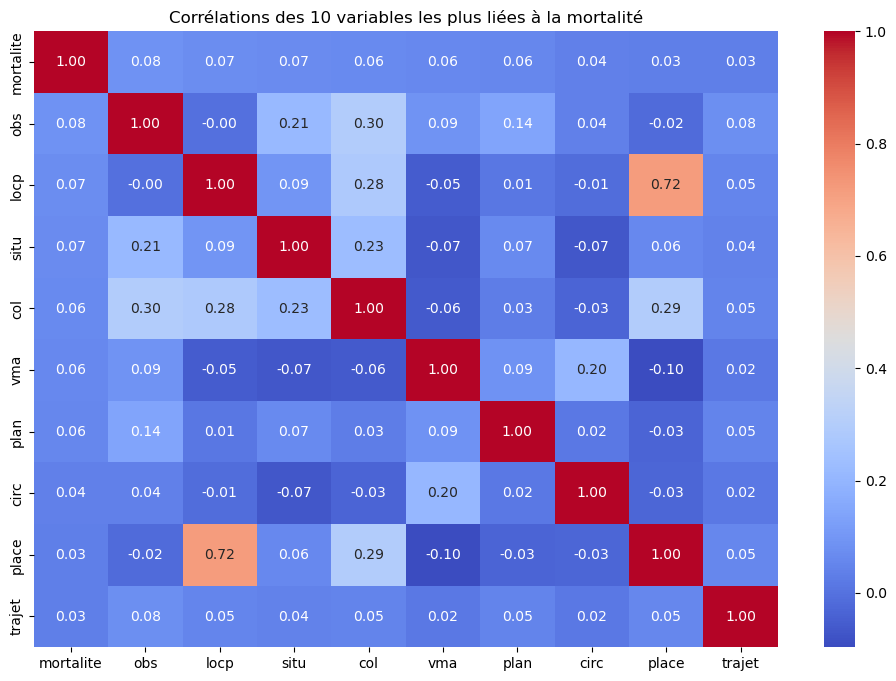

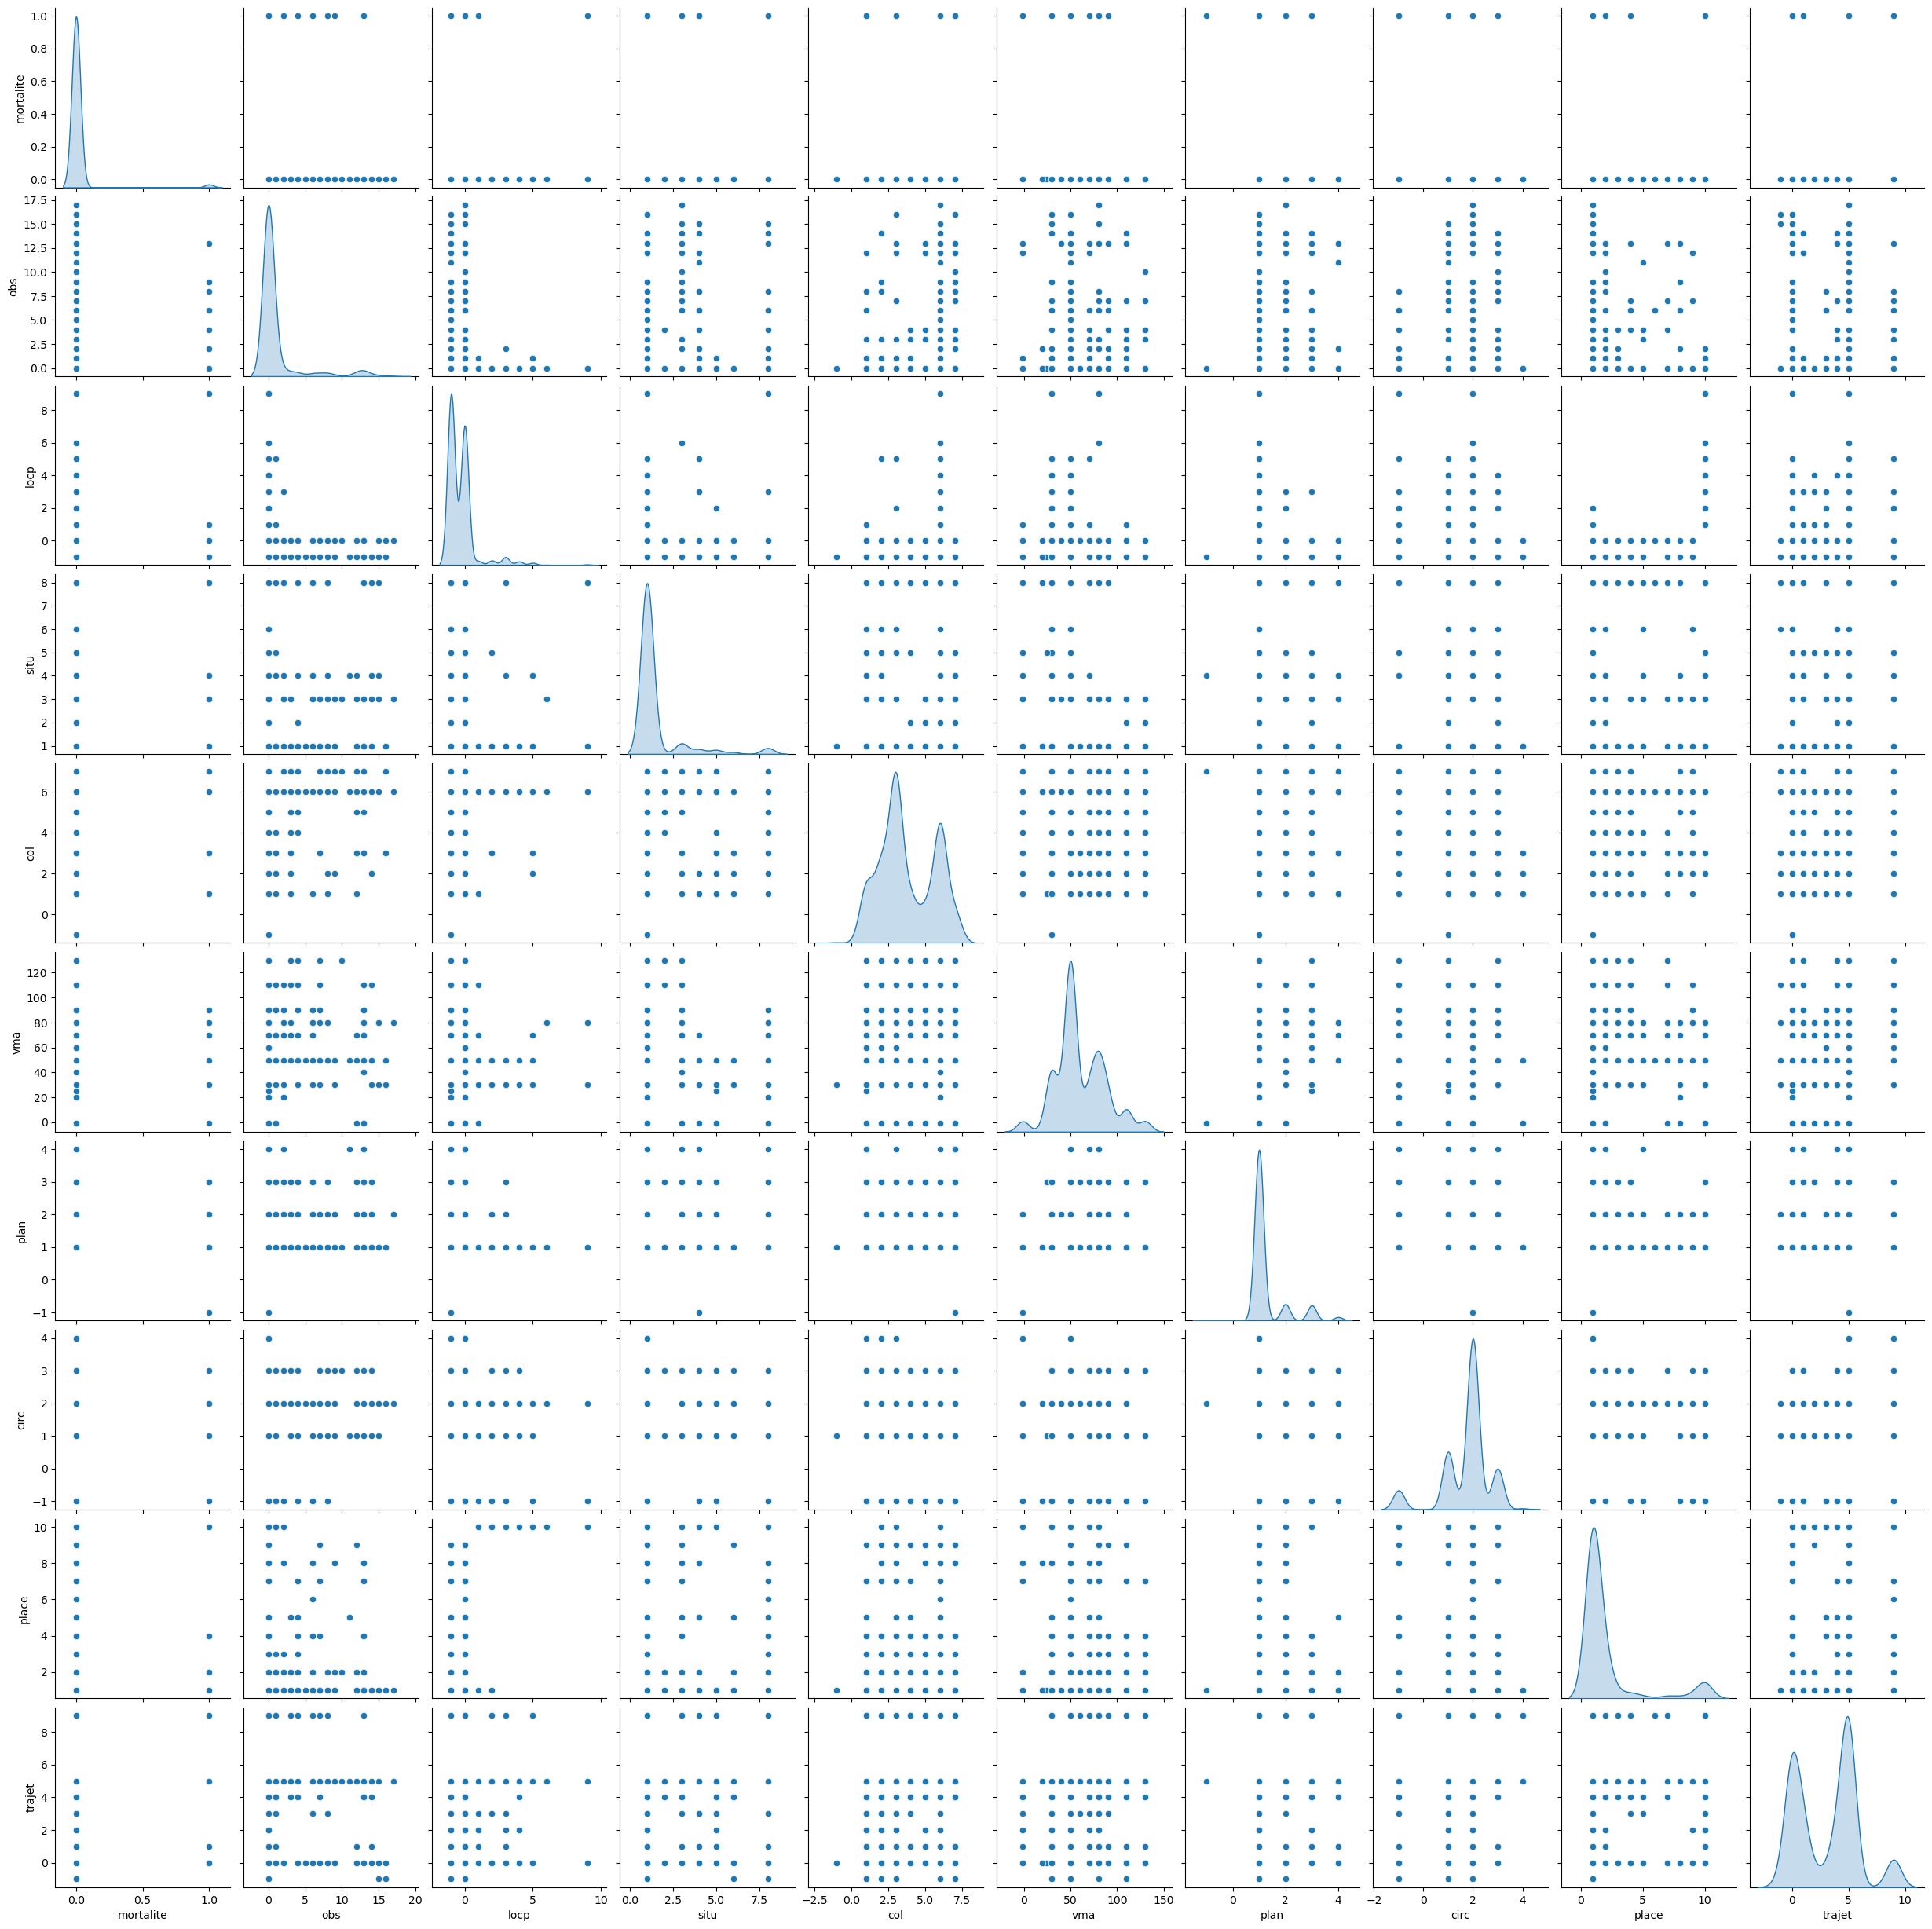

Variables après encodage one-hot :
 Index(['mortalite', 'vma', 'place', 'obs_0', 'obs_1', 'obs_2', 'obs_3',
       'obs_4', 'obs_5', 'obs_6', 'obs_7', 'obs_8', 'obs_9', 'obs_10',
       'obs_11', 'obs_12', 'obs_13', 'obs_14', 'obs_15', 'obs_16', 'obs_17',
       'locp_0', 'locp_1', 'locp_2', 'locp_3', 'locp_4', 'locp_5', 'locp_6',
       'locp_7', 'locp_8', 'locp_9', 'situ_1', 'situ_2', 'situ_3', 'situ_4',
       'situ_5', 'situ_6', 'situ_8', 'col_1', 'col_2', 'col_3', 'col_4',
       'col_5', 'col_6', 'col_7', 'plan_1', 'plan_2', 'plan_3', 'plan_4',
       'circ_1', 'circ_2', 'circ_3', 'circ_4', 'trajet_0', 'trajet_1',
       'trajet_2', 'trajet_3', 'trajet_4', 'trajet_5', 'trajet_9'],
      dtype='object')
Variables les plus corrélées à la mortalité :
 mortalite    1.000000
situ_3       0.111034
obs_2        0.110216
locp_0       0.097164
col_6        0.065420
trajet_5     0.060730
vma          0.060048
col_7        0.057344
locp_1       0.053516
circ_2       0.052903
Name: mortalite

In [ ]:
top_10_features = correlations.index[:10].tolist()
print("Top 10 des variables les plus corrélées à la mortalité :\n", top_10_features)

df_top10 = df_cleaned[top_10_features].select_dtypes(include=[np.number])

plt.figure(figsize=(12, 8))
sns.heatmap(df_top10.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Corrélations des 10 variables les plus liées à la mortalité")
plt.show()

sns.pairplot(df_top10.sample(1000), diag_kind='kde')
plt.show()

top10_list = [col for col in top_10_features if col in df_top10.columns and col not in ['place', 'vma', 'mortalite']]
if top10_list:
    df_top10 = pd.get_dummies(df_top10, columns=top10_list, drop_first=True)
print("Variables après encodage one-hot :\n", df_top10.columns)

correlations2 = (
    df_top10.select_dtypes(include=[np.number, 'bool'])
    .corr(numeric_only=True)['mortalite']
    .sort_values(ascending=False)
)
print("Variables les plus corrélées à la mortalité :\n", correlations2.head(10))

df_top10.to_csv('df_top10.csv', index=False)

y = df_top10['mortalite']
X = df_top10.drop(columns=['mortalite'])

In [ ]:

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:

'''# Hyperparameter grid
param_grid = {
    'C': [1],
    'kernel': ['rbf'],
    'gamma': [0.1]
}

# Grid Search with 5-fold Cross-Validation
grid_svm = GridSearchCV(SVC(probability=True), param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_svm.fit(X_train_scaled, y_train)

print(f"Best Params: {grid_svm.best_params_}")
svm_final = grid_svm.best_estimator_'''

'# Hyperparameter grid\nparam_grid = {\n    \'C\': [1],\n    \'kernel\': [\'rbf\'],\n    \'gamma\': [0.1]\n}\n\n# Grid Search with 5-fold Cross-Validation\ngrid_svm = GridSearchCV(SVC(probability=True), param_grid, cv=5, scoring=\'accuracy\', n_jobs=-1)\ngrid_svm.fit(X_train_scaled, y_train)\n\nprint(f"Best Params: {grid_svm.best_params_}")\nsvm_final = grid_svm.best_estimator_'

In [ ]:
model_nb = GaussianNB()
model_nb.fit(X_train, y_train)

nb_probs = model_nb.predict_proba(X_test)

model_nb_scaled = GaussianNB()
model_nb_scaled.fit(X_train_scaled, y_train)

nb_probs = model_nb_scaled.predict_proba(X_test_scaled)

In [ ]:
X_0 = X_train[y_train == 0]
X_1 = X_train[y_train == 1]

gmm_0 = GaussianMixture(n_components=1, random_state=42).fit(X_0)
gmm_1 = GaussianMixture(n_components=1, random_state=42).fit(X_1)

scores_0 = gmm_0.score_samples(X_test_scaled)
scores_1 = gmm_1.score_samples(X_test_scaled)
y_pred_gmm = np.where(scores_1 > scores_0, 1, 0)

X_0_scaled = X_train_scaled[y_train == 0]
X_1_scaled = X_train_scaled[y_train == 1]

gmm_0_scaled = GaussianMixture(n_components=1, random_state=42).fit(X_0_scaled)
gmm_1_scaled = GaussianMixture(n_components=1, random_state=42).fit(X_1_scaled)

scores_0_scaled = gmm_0_scaled.score_samples(X_test_scaled)
scores_1_scaled = gmm_1_scaled.score_samples(X_test_scaled)
y_pred_gmm_scaled = np.where(scores_1_scaled > scores_0_scaled, 1, 0)

/opt/miniconda3/envs/venvMacOS/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GaussianMixture was fitted with feature names
  warnings.warn(
/opt/miniconda3/envs/venvMacOS/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but GaussianMixture was fitted with feature names
  warnings.warn(


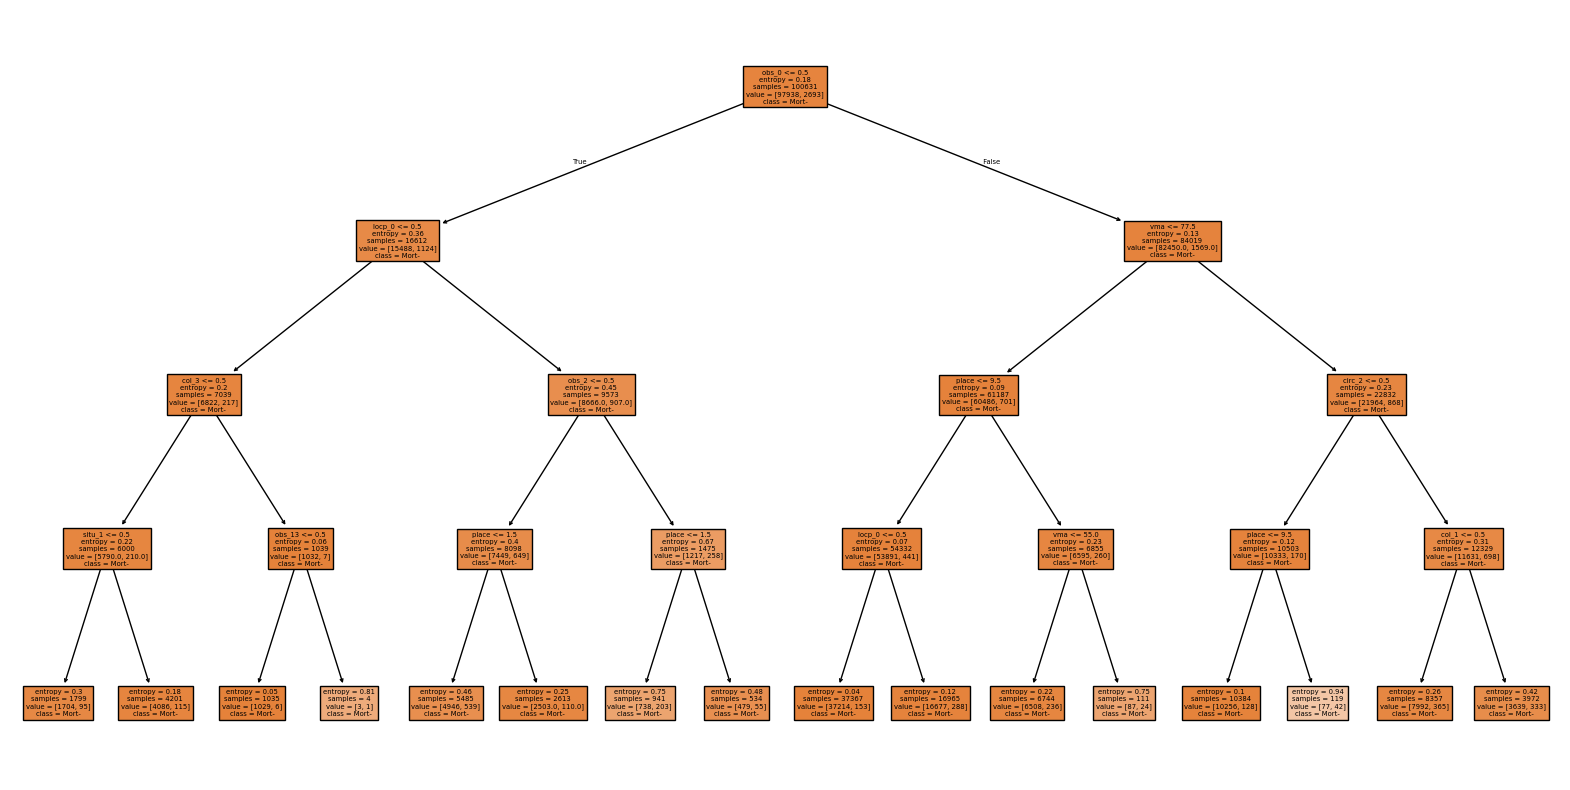

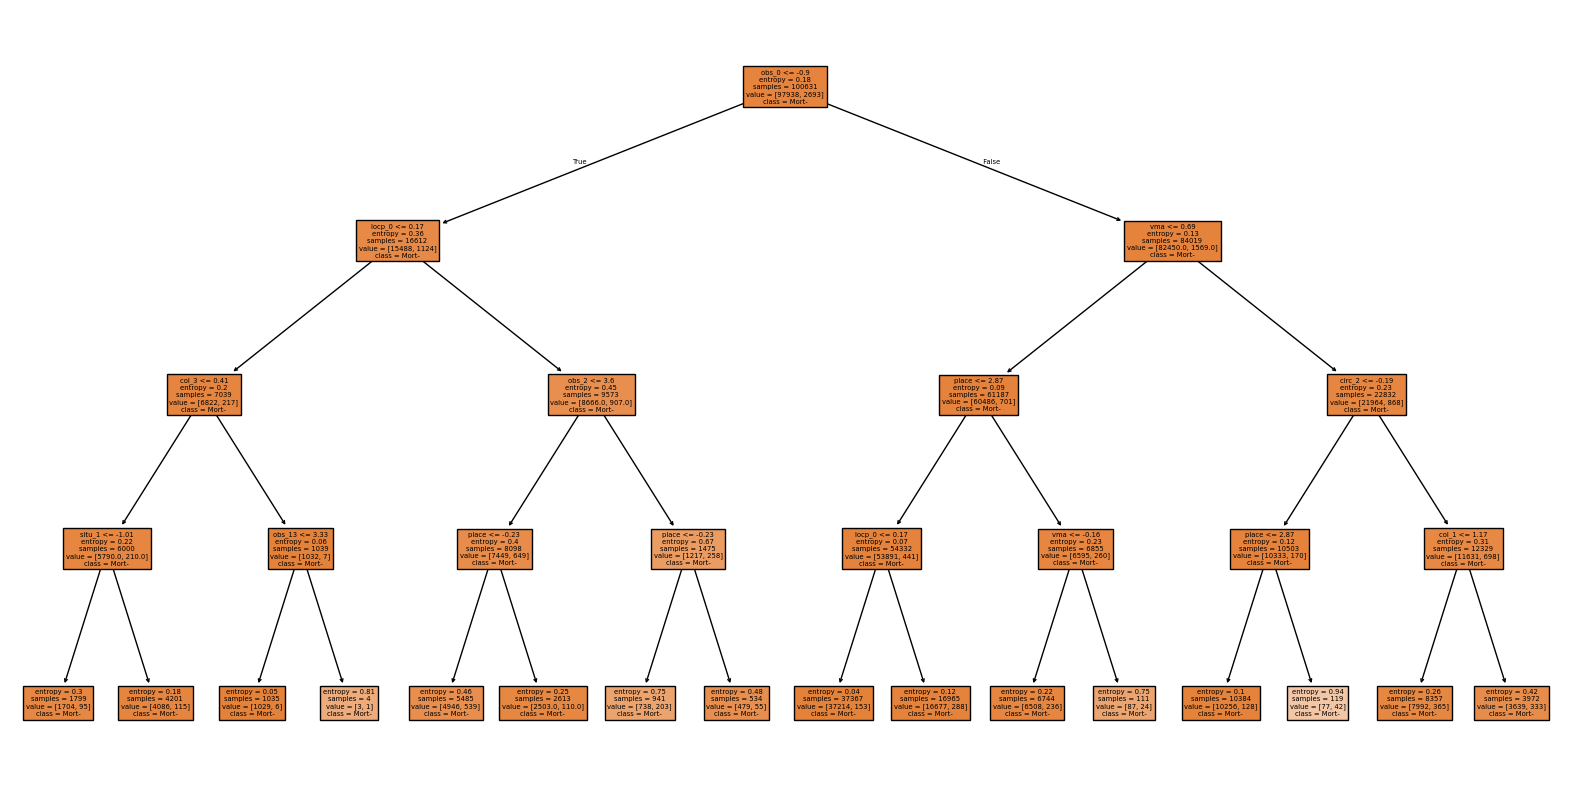

In [ ]:
prob_tree = DecisionTreeClassifier(max_depth=4, criterion='entropy')
prob_tree.fit(X_train, y_train)

plt.figure(figsize=(20,10))
plot_tree(prob_tree, feature_names=X.columns, class_names=['Mort-','Mort+'], filled=True, precision=2)
plt.show()

prob_tree_scaled = DecisionTreeClassifier(max_depth=4, criterion='entropy')
prob_tree_scaled.fit(X_train_scaled, y_train) # Trees don't strictly require scaling

plt.figure(figsize=(20,10))
plot_tree(prob_tree_scaled, feature_names=X.columns, class_names=['Mort-','Mort+'], filled=True, precision=2)
plt.show()

In [ ]:
model_xgb = xgb.XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss'
)

model_xgb.fit(X_train, y_train)
y_pred_xgb = model_xgb.predict(X_test)

model_xgb.fit(X_train_scaled, y_train)
y_pred_xgb_scaled = model_xgb.predict(X_test_scaled)

/opt/miniconda3/envs/venvMacOS/lib/python3.13/site-packages/xgboost/training.py:200: UserWarning: [11:56:57] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/opt/miniconda3/envs/venvMacOS/lib/python3.13/site-packages/xgboost/training.py:200: UserWarning: [11:56:58] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


--- XGBoost Performance ---
              precision    recall  f1-score   support

           0       0.97      1.00      0.99     24453
           1       0.61      0.02      0.03       705

    accuracy                           0.97     25158
   macro avg       0.79      0.51      0.51     25158
weighted avg       0.96      0.97      0.96     25158



In [ ]:
model_lgbm = lgb.LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    num_leaves=31,
    random_state=42
)

model_lgbm.fit(X_train, y_train)
y_pred_lgbm = model_lgbm.predict(X_test)

model_lgbm.fit(X_train_scaled, y_train)
y_pred_lgbm_scaled = model_lgbm.predict(X_test_scaled)

[LightGBM] [Info] Number of positive: 2693, number of negative: 97938
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.005886 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 143
[LightGBM] [Info] Number of data points in the train set: 100631, number of used features: 58
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.026761 -> initscore=-3.593679
[LightGBM] [Info] Start training from score -3.593679
[LightGBM] [Info] Number of positive: 2693, number of negative: 97938
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.011864 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 198
[LightGBM] [Info] Number of data points in the train set: 100631, number of used features: 58
[LightGBM] [Info] [b

/opt/miniconda3/envs/venvMacOS/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [ ]:
models = {
    "Naive Bayes": model_nb.predict(X_test),
    "Naive Bayes Scaled": model_nb_scaled.predict(X_test_scaled),
    "GMM Classifier": y_pred_gmm,
    "GMM Classifier Scaled": y_pred_gmm_scaled,
    "Decision Tree": prob_tree.predict(X_test),
    "Decision Tree Scaled": prob_tree_scaled.predict(X_test_scaled),
    "XGBoost": y_pred_xgb,
    "XGBoost Scaled": y_pred_xgb_scaled,
    "LightGBM": y_pred_lgbm,
    "LightGBM Scaled": y_pred_lgbm_scaled
}

for name, preds in models.items():
    print(f"--- {name} ---")
    print(classification_report(y_test, preds))
    print(f"Confusion Matrix:\n{pd.crosstab(y_test, preds, rownames=['Actual'], colnames=['Predicted'])}\n")
    print(f"Accuracy: {accuracy_score(y_test, preds):.4f}")
    print(f"F1-Score: {f1_score(y_test, preds):.4f}")
    print(f"ROC-AUC: {roc_auc_score(y_test, preds):.4f}\n")

--- Naive Bayes ---
              precision    recall  f1-score   support

           0       0.98      0.84      0.91     24453
           1       0.09      0.52      0.15       705

    accuracy                           0.83     25158
   macro avg       0.53      0.68      0.53     25158
weighted avg       0.96      0.83      0.88     25158

Confusion Matrix:
Predicted      0     1
Actual                
0          20510  3943
1            336   369

Accuracy: 0.8299
F1-Score: 0.1471
ROC-AUC: 0.6811

--- Naive Bayes Scaled ---
              precision    recall  f1-score   support

           0       0.99      0.76      0.86     24453
           1       0.07      0.64      0.13       705

    accuracy                           0.76     25158
   macro avg       0.53      0.70      0.49     25158
weighted avg       0.96      0.76      0.84     25158

Confusion Matrix:
Predicted      0     1
Actual                
0          18568  5885
1            253   452

Accuracy: 0.7560
F1-Score:

/opt/miniconda3/envs/venvMacOS/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/miniconda3/envs/venvMacOS/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/miniconda3/envs/venvMacOS/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()}

/opt/miniconda3/envs/venvMacOS/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/miniconda3/envs/venvMacOS/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/miniconda3/envs/venvMacOS/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()}

Best true positive rate achieved by: GMM Classifier Scaled
--- Top 5 Features driving GMM clusters ---
circ_2      0.408383
obs_0       0.180068
col_4       0.139876
trajet_2    0.130418
circ_3      0.129872
dtype: float64
--- Variables that shift an accident toward 'Mortalité' in GMM ---
obs_2     0.680969
situ_3    0.676173
locp_0    0.611340
col_6     0.393134
vma       0.383707
dtype: float64


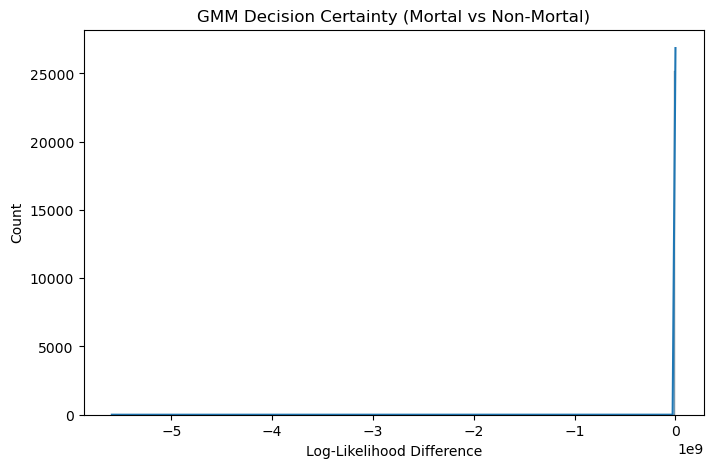

In [ ]:
print("Best true positive rate achieved by:", max(models, key=lambda name: classification_report(y_test, models[name], output_dict=True)['1']['recall']))

from sklearn.tree import plot_tree

tree_gmm = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_gmm.fit(X_test_scaled, y_pred_gmm_scaled)
importances_gmm = pd.Series(tree_gmm.feature_importances_, index=X.columns).sort_values(ascending=False)

print("--- Top 5 Features driving GMM clusters ---")
print(importances_gmm.head(5))

mean_diff = pd.Series(gmm_1_scaled.means_[0] - gmm_0_scaled.means_[0], index=X_train.columns)

print("--- Variables that shift an accident toward 'Mortalité' in GMM ---")
print(mean_diff.sort_values(ascending=False).head(5))

probs_mortal = gmm_1_scaled.score_samples(X_test_scaled) - gmm_0_scaled.score_samples(X_test_scaled) # Difference in likelihood

plt.figure(figsize=(8,5))
sns.histplot(probs_mortal, kde=True)
plt.title("GMM Decision Certainty (Mortal vs Non-Mortal)")
plt.xlabel("Log-Likelihood Difference")
plt.show()